  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Libraries imported successfully!

Dataset downloaded successfully!

First five records:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       1  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

Dataset shape: (297, 14)

Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope'

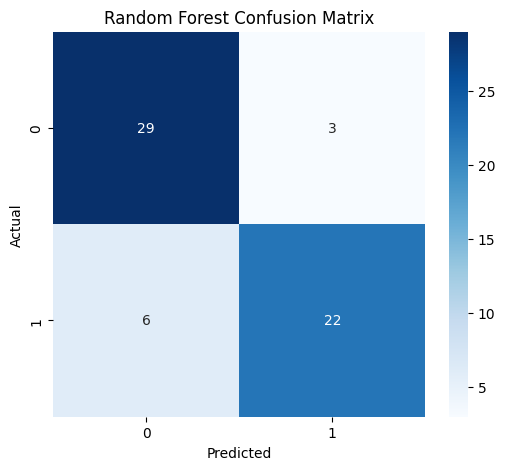


Global Feature Importance:
     Feature  Importance
2         cp    0.144703
12      thal    0.134960
7    thalach    0.114664
9    oldpeak    0.102924
11        ca    0.097248
0        age    0.088711
4       chol    0.085626
3   trestbps    0.079664
10     slope    0.052608
8      exang    0.041914
1        sex    0.025338
6    restecg    0.021788
5        fbs    0.009853


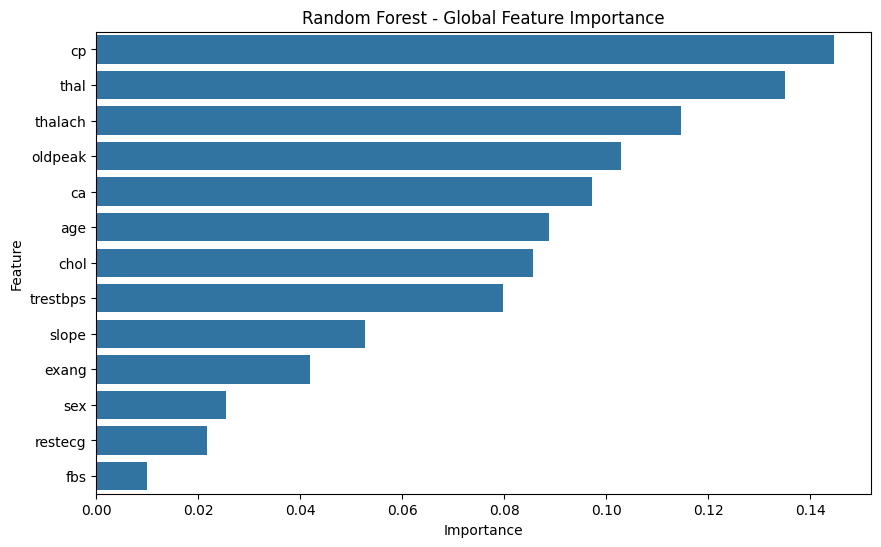


SHAP analysis completed!


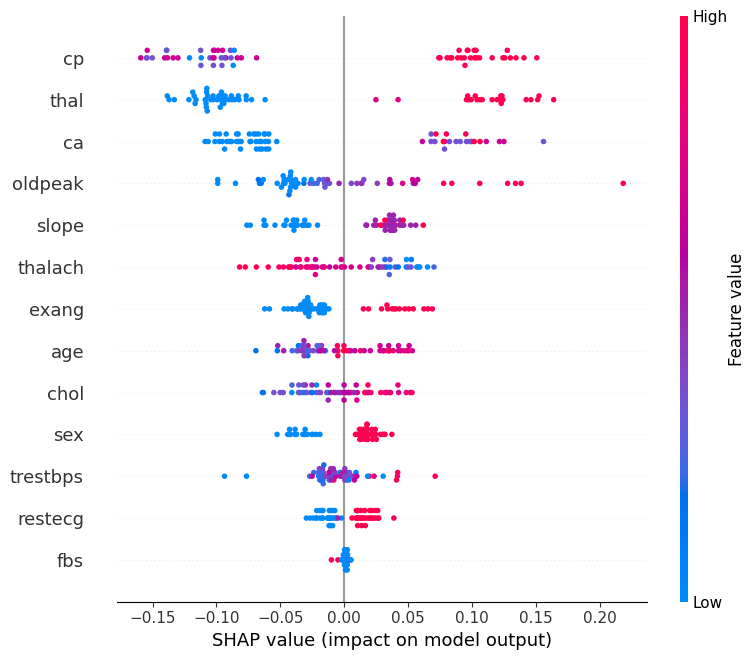


SHAP EXPLANATION FOR TEST INSTANCE 1
Actual Class: 0
Predicted Class: 0
Probability of Heart Disease: 4.99 %


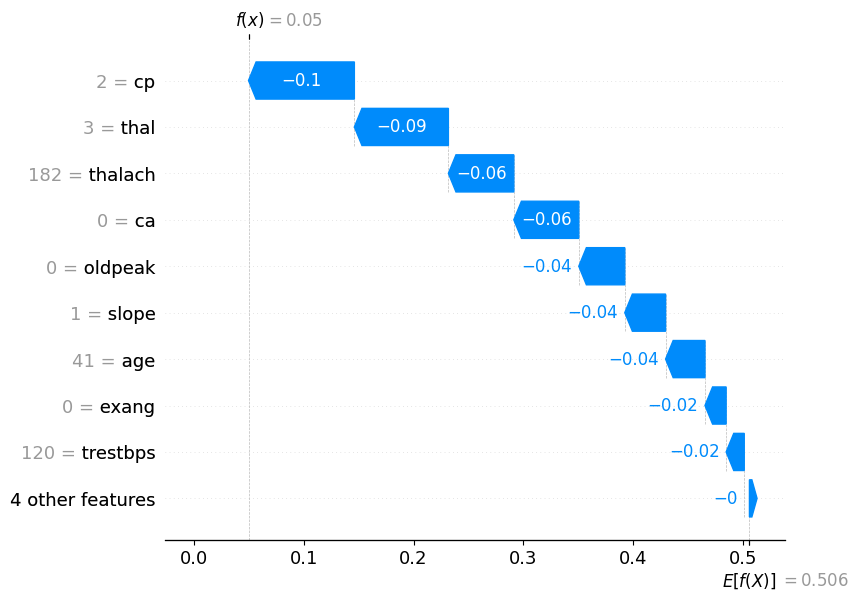


Top 5 Important Features:
    Feature  SHAP Value  Absolute SHAP
2        cp   -0.096312       0.096312
12     thal   -0.085543       0.085543
7   thalach   -0.059535       0.059535
11       ca   -0.059107       0.059107
9   oldpeak   -0.041845       0.041845

SHAP EXPLANATION FOR TEST INSTANCE 2
Actual Class: 0
Predicted Class: 0
Probability of Heart Disease: 12.4 %


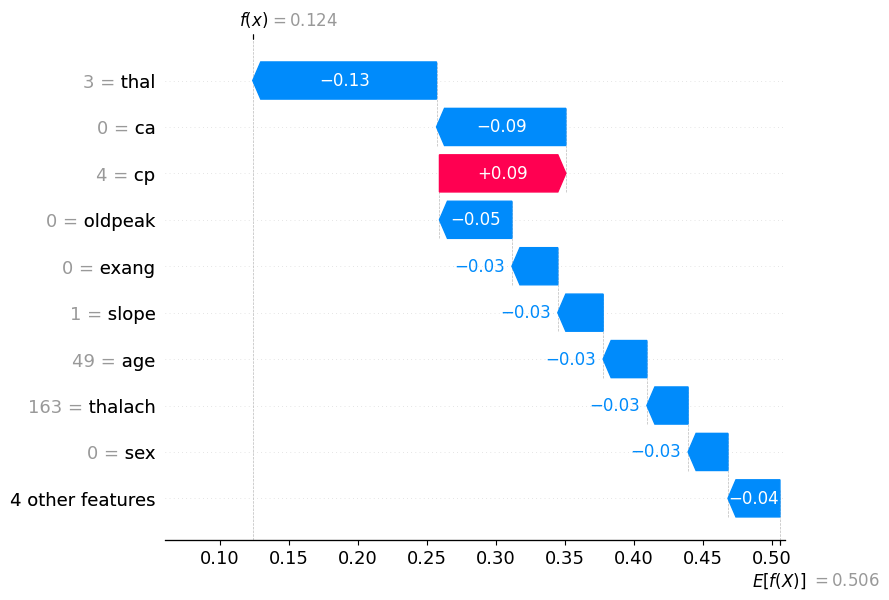


Top 5 Important Features:
    Feature  SHAP Value  Absolute SHAP
12     thal   -0.133027       0.133027
11       ca   -0.093628       0.093628
2        cp    0.091508       0.091508
9   oldpeak   -0.052479       0.052479
8     exang   -0.033208       0.033208

LIME EXPLANATION FOR TEST INSTANCE 1
Actual Class: 0
Predicted Class: 0
Probability of Heart Disease: 4.99 %

LIME Feature Contributions:
[('cp <= 3.00', -0.18300721353224197), ('ca <= 0.00', -0.1761109240075334), ('thal <= 3.00', -0.17279741700632628), ('slope <= 1.00', -0.07691438684212315), ('oldpeak <= 0.00', -0.0677947293823647), ('thalach > 166.00', -0.059304731057546106), ('0.00 < sex <= 1.00', 0.052397971299892626), ('chol <= 212.00', -0.049873071912056366), ('exang <= 0.00', -0.04519658716662745), ('age <= 48.00', -0.04004354051550212), ('trestbps <= 120.00', -0.029495854889467255), ('restecg <= 0.00', -0.0293655072893068), ('fbs <= 0.00', 0.00834533506058392)]


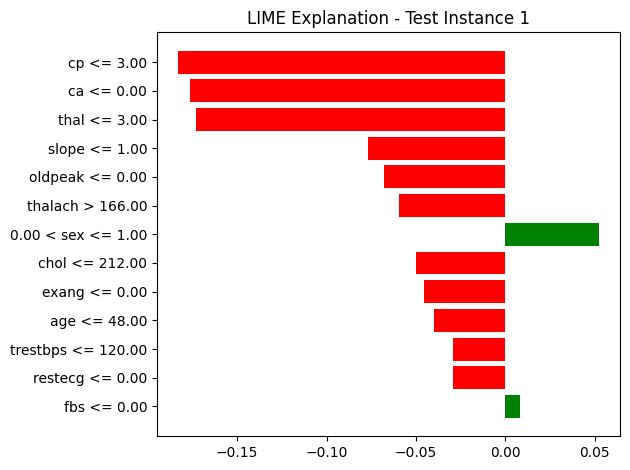


LIME EXPLANATION FOR TEST INSTANCE 2
Actual Class: 0
Predicted Class: 0
Probability of Heart Disease: 12.4 %

LIME Feature Contributions:
[('3.00 < cp <= 4.00', 0.18617249609472347), ('thal <= 3.00', -0.17687139762020898), ('ca <= 0.00', -0.17122111937765339), ('slope <= 1.00', -0.0772286814401797), ('oldpeak <= 0.00', -0.06496120444712308), ('sex <= 0.00', -0.056074153944532426), ('exang <= 0.00', -0.0467473602724631), ('restecg <= 0.00', -0.03136646615528913), ('243.00 < chol <= 277.00', 0.02378739498000034), ('48.00 < age <= 56.00', -0.020729377374556206), ('fbs <= 0.00', 0.011280599005861744), ('152.00 < thalach <= 166.00', -0.004032854697034441), ('120.00 < trestbps <= 130.00', -0.0012992027651630726)]


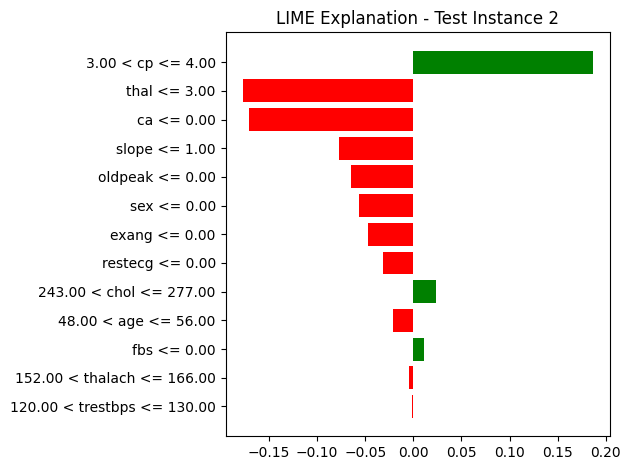


FEATURE IMPORTANCE COMPARISON
TEST INSTANCE 1

Top SHAP Features:
    Feature  SHAP Importance
2        cp         0.096312
12     thal         0.085543
7   thalach         0.059535
11       ca         0.059107
9   oldpeak         0.041845

Top LIME Features:
           Feature  LIME Contribution
0       cp <= 3.00          -0.184280
1       ca <= 0.00          -0.176233
2     thal <= 3.00          -0.169935
3    slope <= 1.00          -0.074886
4  oldpeak <= 0.00          -0.069222

FEATURE IMPORTANCE COMPARISON
TEST INSTANCE 2

Top SHAP Features:
    Feature  SHAP Importance
12     thal         0.133027
11       ca         0.093628
2        cp         0.091508
9   oldpeak         0.052479
8     exang         0.033208

Top LIME Features:
             Feature  LIME Contribution
0  3.00 < cp <= 4.00           0.185584
1         ca <= 0.00          -0.179526
2       thal <= 3.00          -0.175841
3      slope <= 1.00          -0.072992
4    oldpeak <= 0.00          -0.069634


FINAL MO

In [1]:
!pip -q install shap lime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from lime.lime_tabular import LimeTabularExplainer

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")



url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'target'
]

df = pd.read_csv(url, names=columns, na_values='?')

df = df.apply(pd.to_numeric, errors='coerce')
df.dropna(inplace=True)



df['target'] = (df['target'] > 0).astype(int)

print("\nDataset downloaded successfully!")
print("\nFirst five records:")
print(df.head())

print("\nDataset shape:", df.shape)



X = df.drop('target', axis=1)
y = df['target']

feature_names = X.columns.tolist()

print("\nFeatures:")
print(feature_names)



X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))



model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("\nRandom Forest model trained successfully!")


y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nGlobal Feature Importance:")
print(importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest - Global Feature Importance")
plt.show()



explainer = shap.TreeExplainer(model)


shap_values = explainer.shap_values(X_test)

print("\nSHAP analysis completed!")

if isinstance(shap_values, list):
    positive_shap = shap_values[1]
elif len(shap_values.shape) == 3:
    positive_shap = shap_values[:, :, 1]
else:
    positive_shap = shap_values


shap.summary_plot(
    positive_shap,
    X_test,
    feature_names=feature_names,
    show=True
)


shap_explanation = explainer(X_test)

if len(shap_explanation.shape) == 3:
    positive_explanation = shap_explanation[:, :, 1]
else:
    positive_explanation = shap_explanation

for i in range(2):

    print("\n====================================")
    print("SHAP EXPLANATION FOR TEST INSTANCE", i + 1)
    print("====================================")

    print("Actual Class:", y_test.iloc[i])
    print("Predicted Class:", y_pred[i])
    print(
        "Probability of Heart Disease:",
        round(y_prob[i] * 100, 2), "%"
    )

    shap.plots.waterfall(
        positive_explanation[i],
        show=True
    )

    local_importance = pd.DataFrame({
        'Feature': feature_names,
        'SHAP Value': positive_shap[i]
    })

    local_importance['Absolute SHAP'] = (
        local_importance['SHAP Value'].abs()
    )

    local_importance = local_importance.sort_values(
        by='Absolute SHAP',
        ascending=False
    )

    print("\nTop 5 Important Features:")
    print(local_importance.head(5))


lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=['No Disease', 'Heart Disease'],
    mode='classification',
    discretize_continuous=True,
    random_state=42
)


for i in range(2):

    print("\n====================================")
    print("LIME EXPLANATION FOR TEST INSTANCE", i + 1)
    print("====================================")

    instance = X_test.iloc[i].values

    lime_exp = lime_explainer.explain_instance(
        data_row=instance,
        predict_fn=model.predict_proba,
        num_features=13,
        num_samples=5000
    )

    print("Actual Class:", y_test.iloc[i])
    print("Predicted Class:", y_pred[i])

    print(
        "Probability of Heart Disease:",
        round(y_prob[i] * 100, 2), "%"
    )

    print("\nLIME Feature Contributions:")

    print(
        lime_exp.as_list(label=1)
    )

    fig = lime_exp.as_pyplot_figure(label=1)

    plt.title("LIME Explanation - Test Instance " + str(i + 1))
    plt.tight_layout()
    plt.show()



for i in range(2):

    shap_importance = pd.DataFrame({
        'Feature': feature_names,
        'SHAP Importance': np.abs(positive_shap[i])
    })

    lime_exp = lime_explainer.explain_instance(
        X_test.iloc[i].values,
        model.predict_proba,
        num_features=13,
        num_samples=5000
    )

    lime_importance = pd.DataFrame(
        lime_exp.as_list(label=1),
        columns=['Feature', 'LIME Contribution']
    )

    shap_importance = shap_importance.sort_values(
        by='SHAP Importance',
        ascending=False
    )

    print("\n====================================")
    print("FEATURE IMPORTANCE COMPARISON")
    print("TEST INSTANCE", i + 1)
    print("====================================")

    print("\nTop SHAP Features:")
    print(shap_importance.head(5))

    print("\nTop LIME Features:")
    print(lime_importance.head(5))



print("\n")
print("=" * 60)
print("FINAL MODEL INTERPRETABILITY REPORT")
print("=" * 60)

print("\nDataset: UCI Heart Disease Dataset")
print("Algorithm: Random Forest Classifier")
print("Explainability Techniques: SHAP and LIME")

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

for i in range(2):

    print("\n--------------------------------------")
    print("TEST INSTANCE:", i + 1)
    print("--------------------------------------")

    print("Actual Outcome:", int(y_test.iloc[i]))

    print("Predicted Outcome:", int(y_pred[i]))

    print(
        "Heart Disease Probability:",
        round(y_prob[i] * 100, 2), "%"
    )

    print("\nTop 3 SHAP Features:")

    top_features = np.argsort(
        np.abs(positive_shap[i])
    )[::-1][:3]

    for index in top_features:

        direction = (
            "increases"
            if positive_shap[i][index] > 0
            else "decreases"
        )

        print(
            feature_names[index],
            ":", round(positive_shap[i][index], 4),
            "(", direction, "predicted probability )"
        )

print("\n")
print("=" * 60)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("=" * 60)
